In [ ]:
import pandas as pd;

In [ ]:
df=pd.read_csv("/content/IPL.csv")

/tmp/ipykernel_1069/2720646102.py:1: DtypeWarning: Columns (27,28,29,30,42,45,46,47,50) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv("/content/IPL.csv")


In [ ]:
df.head()

,match_id,date,match_type,event_name,innings,batting_team,bowling_team,over,ball,ball_no,...,team_balls,team_wicket,new_batter,power_surge_start,batter_runs,batter_balls,bowler_wicket,batting_partners,striker_out,next_batter
0,335982,2008-04-18,T20,Indian Premier League,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,0.1,...,1,0,NaN,NaN,0,1,0,BB McCullum|SC Ganguly,0,NaN
1,335982,2008-04-18,T20,Indian Premier League,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,0.2,...,2,0,NaN,NaN,0,1,0,BB McCullum|SC Ganguly,0,NaN
2,335982,2008-04-18,T20,Indian Premier League,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,0.3,...,2,0,NaN,NaN,0,1,0,BB McCullum|SC Ganguly,0,NaN
3,335982,2008-04-18,T20,Indian Premier League,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,0.3,...,3,0,NaN,NaN,0,2,0,BB McCullum|SC Ganguly,0,NaN
4,335982,2008-04-18,T20,Indian Premier League,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,0.4,...,4,0,NaN,NaN,0,3,0,BB McCullum|SC Ganguly,0,NaN


In [ ]:
df.columns

Index(['match_id', 'date', 'match_type', 'event_name', 'innings',
       'batting_team', 'bowling_team', 'over', 'ball', 'ball_no', 'batter',
       'bat_pos', 'runs_batter', 'balls_faced', 'bowler', 'valid_ball',
       'runs_extras', 'runs_total', 'runs_bowler', 'runs_not_boundary',
       'extra_type', 'non_striker', 'non_striker_pos', 'wicket_kind',
       'player_out', 'fielders', 'runs_target', 'review_batter',
       'team_reviewed', 'review_decision', 'umpire', 'umpires_call',
       'player_of_match', 'match_won_by', 'win_outcome', 'toss_winner',
       'toss_decision', 'venue', 'city', 'day', 'month', 'year', 'season',
       'gender', 'team_type', 'superover_winner', 'result_type', 'method',
       'balls_per_over', 'overs', 'event_match_no', 'stage', 'match_number',
       'team_runs', 'team_balls', 'team_wicket', 'new_batter',
       'power_surge_start', 'batter_runs', 'batter_balls', 'bowler_wicket',
       'batting_partners', 'striker_out', 'next_batter'],
      dtype='o

In [ ]:
df.shape

(295732, 64)

In [ ]:
df.isnull().sum()

,0
match_id,0
date,0
match_type,0
event_name,0
innings,0
...,...
batter_balls,0
bowler_wicket,0
batting_partners,0
striker_out,0


In [ ]:
df['match_id'].nunique()

1243

In [ ]:
df.groupby('match_id').size().describe()

,0
count,1243.000000
mean,237.917940
std,23.208944
min,22.000000
25%,236.000000
50%,245.000000
75%,249.000000
max,269.000000


In [ ]:
df[['match_id','date','batting_team','bowling_team','match_won_by']].head()

,match_id,date,batting_team,bowling_team,match_won_by
0,335982,2008-04-18,Kolkata Knight Riders,Royal Challengers Bangalore,Kolkata Knight Riders
1,335982,2008-04-18,Kolkata Knight Riders,Royal Challengers Bangalore,Kolkata Knight Riders
2,335982,2008-04-18,Kolkata Knight Riders,Royal Challengers Bangalore,Kolkata Knight Riders
3,335982,2008-04-18,Kolkata Knight Riders,Royal Challengers Bangalore,Kolkata Knight Riders
4,335982,2008-04-18,Kolkata Knight Riders,Royal Challengers Bangalore,Kolkata Knight Riders


In [ ]:
df[df['match_id']==335982][['match_id','date','batting_team','bowling_team','match_won_by']].drop_duplicates()

,match_id,date,batting_team,bowling_team,match_won_by
0,335982,2008-04-18,Kolkata Knight Riders,Royal Challengers Bangalore,Kolkata Knight Riders
124,335982,2008-04-18,Royal Challengers Bangalore,Kolkata Knight Riders,Kolkata Knight Riders


In [ ]:
match_df=df.groupby('match_id').agg({
    'date':'first',
    'batting_team':'first',
    'bowling_team':'first',
    'toss_winner': 'first',
    'toss_decision': 'first',
    'venue':'first',
    'city':'first',
    'season':'first',
    'match_won_by':'first',
}).reset_index()

In [ ]:
match_df

,match_id,date,batting_team,bowling_team,toss_winner,toss_decision,venue,city,season,match_won_by
0,335982,2008-04-18,Kolkata Knight Riders,Royal Challengers Bangalore,Royal Challengers Bangalore,field,M Chinnaswamy Stadium,Bangalore,2007/08,Kolkata Knight Riders
1,335983,2008-04-19,Chennai Super Kings,Kings XI Punjab,Chennai Super Kings,bat,"Punjab Cricket Association Stadium, Mohali",Chandigarh,2007/08,Chennai Super Kings
2,335984,2008-04-19,Rajasthan Royals,Delhi Daredevils,Rajasthan Royals,bat,Feroz Shah Kotla,Delhi,2007/08,Delhi Daredevils
3,335985,2008-04-20,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Wankhede Stadium,Mumbai,2007/08,Royal Challengers Bangalore
4,335986,2008-04-20,Deccan Chargers,Kolkata Knight Riders,Deccan Chargers,bat,Eden Gardens,Kolkata,2007/08,Kolkata Knight Riders
...,...,...,...,...,...,...,...,...,...,...
1238,1529313,2026-05-24,Delhi Capitals,Kolkata Knight Riders,Kolkata Knight Riders,field,"Eden Gardens, Kolkata",Kolkata,2026,Delhi Capitals
1239,1535462,2026-05-26,Royal Challengers Bengaluru,Gujarat Titans,Gujarat Titans,field,"Himachal Pradesh Cricket Association Stadium, ...",Dharamsala,2026,Royal Challengers Bengaluru
1240,1535463,2026-05-27,Rajasthan Royals,Sunrisers Hyderabad,Sunrisers Hyderabad,field,Maharaja Yadavindra Singh International Cricke...,New Chandigarh,2026,Rajasthan Royals
1241,1535464,2026-05-29,Rajasthan Royals,Gujarat Titans,Rajasthan Royals,bat,Maharaja Yadavindra Singh International Cricke...,New Chandigarh,2026,Gujarat Titans


In [ ]:
team_check=df.groupby('match_id').agg({
    'batting_team':lambda x:list(x.unique()),
    'bowling_team':lambda x:list(x.unique()),
    'match_won_by':'first'
}).reset_index()

In [ ]:
team_check

,match_id,batting_team,bowling_team,match_won_by
0,335982,"[Kolkata Knight Riders, Royal Challengers Bang...","[Royal Challengers Bangalore, Kolkata Knight R...",Kolkata Knight Riders
1,335983,"[Chennai Super Kings, Kings XI Punjab]","[Kings XI Punjab, Chennai Super Kings]",Chennai Super Kings
2,335984,"[Rajasthan Royals, Delhi Daredevils]","[Delhi Daredevils, Rajasthan Royals]",Delhi Daredevils
3,335985,"[Mumbai Indians, Royal Challengers Bangalore]","[Royal Challengers Bangalore, Mumbai Indians]",Royal Challengers Bangalore
4,335986,"[Deccan Chargers, Kolkata Knight Riders]","[Kolkata Knight Riders, Deccan Chargers]",Kolkata Knight Riders
...,...,...,...,...
1238,1529313,"[Delhi Capitals, Kolkata Knight Riders]","[Kolkata Knight Riders, Delhi Capitals]",Delhi Capitals
1239,1535462,"[Royal Challengers Bengaluru, Gujarat Titans]","[Gujarat Titans, Royal Challengers Bengaluru]",Royal Challengers Bengaluru
1240,1535463,"[Rajasthan Royals, Sunrisers Hyderabad]","[Sunrisers Hyderabad, Rajasthan Royals]",Rajasthan Royals
1241,1535464,"[Rajasthan Royals, Gujarat Titans]","[Gujarat Titans, Rajasthan Royals]",Gujarat Titans


In [ ]:
print(team_check['batting_team'].apply(len).value_counts())
print(team_check['bowling_team'].apply(len).value_counts())


batting_team
2    1237
1       6
Name: count, dtype: int64
bowling_team
2    1237
1       6
Name: count, dtype: int64


In [ ]:
team_names=df.groupby('match_id')['batting_team'].unique()

In [ ]:
team_names

,batting_team
match_id,
335982,"[Kolkata Knight Riders, Royal Challengers Bang..."
335983,"[Chennai Super Kings, Kings XI Punjab]"
335984,"[Rajasthan Royals, Delhi Daredevils]"
335985,"[Mumbai Indians, Royal Challengers Bangalore]"
335986,"[Deccan Chargers, Kolkata Knight Riders]"
...,...
1529313,"[Delhi Capitals, Kolkata Knight Riders]"
1535462,"[Royal Challengers Bengaluru, Gujarat Titans]"
1535463,"[Rajasthan Royals, Sunrisers Hyderabad]"


In [ ]:
team_names = df.groupby('match_id')['batting_team'].unique()

problem_matches = team_names[team_names.apply(len) < 2]

problem_matches

,batting_team
match_id,
501265,[Delhi Daredevils]
829763,[Royal Challengers Bangalore]
1359519,[Lucknow Super Giants]
1473492,[Delhi Capitals]
1473495,[Punjab Kings]
1527685,[Kolkata Knight Riders]


In [ ]:
len(problem_matches)

6

In [ ]:
df[df['match_id'].isin(problem_matches.index)][
    ['match_id', 'date', 'batting_team', 'bowling_team', 'match_won_by']
].drop_duplicates().head(20)

,match_id,date,batting_team,bowling_team,match_won_by
57068,501265,2011-05-21,Delhi Daredevils,Pune Warriors,Unknown
115353,829763,2015-04-29,Royal Challengers Bangalore,Rajasthan Royals,Unknown
236750,1359519,2023-05-03,Lucknow Super Giants,Chennai Super Kings,Unknown
273705,1473492,2025-05-05,Delhi Capitals,Sunrisers Hyderabad,Unknown
274316,1473495,2025-05-08,Punjab Kings,Delhi Capitals,Unknown
280816,1527685,2026-04-06,Kolkata Knight Riders,Punjab Kings,Unknown


In [ ]:
match_df = match_df[
    ~match_df['match_id'].isin(problem_matches.index)
].copy()

In [ ]:
match_df.shape

(1237, 10)

In [ ]:
match_df.head()

,match_id,date,batting_team,bowling_team,toss_winner,toss_decision,venue,city,season,match_won_by
0,335982,2008-04-18,Kolkata Knight Riders,Royal Challengers Bangalore,Royal Challengers Bangalore,field,M Chinnaswamy Stadium,Bangalore,2007/08,Kolkata Knight Riders
1,335983,2008-04-19,Chennai Super Kings,Kings XI Punjab,Chennai Super Kings,bat,"Punjab Cricket Association Stadium, Mohali",Chandigarh,2007/08,Chennai Super Kings
2,335984,2008-04-19,Rajasthan Royals,Delhi Daredevils,Rajasthan Royals,bat,Feroz Shah Kotla,Delhi,2007/08,Delhi Daredevils
3,335985,2008-04-20,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Wankhede Stadium,Mumbai,2007/08,Royal Challengers Bangalore
4,335986,2008-04-20,Deccan Chargers,Kolkata Knight Riders,Deccan Chargers,bat,Eden Gardens,Kolkata,2007/08,Kolkata Knight Riders


In [ ]:
teams = df.groupby('match_id').agg({
    'batting_team': lambda x: list(x.unique()),
    'bowling_team': lambda x: list(x.unique())
})

In [ ]:
match_df['team1'] = match_df['match_id'].map(
    lambda x: teams.loc[x, 'batting_team'][0]
)

match_df['team2'] = match_df['match_id'].map(
    lambda x: teams.loc[x, 'bowling_team'][0]
)

In [ ]:
match_df[['match_id', 'team1', 'team2', 'match_won_by']].head(10)

,match_id,team1,team2,match_won_by
0,335982,Kolkata Knight Riders,Royal Challengers Bangalore,Kolkata Knight Riders
1,335983,Chennai Super Kings,Kings XI Punjab,Chennai Super Kings
2,335984,Rajasthan Royals,Delhi Daredevils,Delhi Daredevils
3,335985,Mumbai Indians,Royal Challengers Bangalore,Royal Challengers Bangalore
4,335986,Deccan Chargers,Kolkata Knight Riders,Kolkata Knight Riders
5,335987,Kings XI Punjab,Rajasthan Royals,Rajasthan Royals
6,335988,Deccan Chargers,Delhi Daredevils,Delhi Daredevils
7,335989,Chennai Super Kings,Mumbai Indians,Chennai Super Kings
8,335990,Deccan Chargers,Rajasthan Royals,Rajasthan Royals
9,335991,Kings XI Punjab,Mumbai Indians,Kings XI Punjab


In [ ]:
match_df['match_won_by'].value_counts()

,count
match_won_by,
Mumbai Indians,155
Chennai Super Kings,148
Kolkata Knight Riders,140
Rajasthan Royals,123
Royal Challengers Bangalore,114
Sunrisers Hyderabad,102
Kings XI Punjab,85
Delhi Daredevils,67
Delhi Capitals,58


In [ ]:
match_df['match_won_by'].isnull().sum()

np.int64(0)

In [ ]:
match_df=match_df[match_df['match_won_by']!='Unknown'].copy()

In [ ]:
match_df['match_won_by'].value_counts()

,count
match_won_by,
Mumbai Indians,155
Chennai Super Kings,148
Kolkata Knight Riders,140
Rajasthan Royals,123
Royal Challengers Bangalore,114
Sunrisers Hyderabad,102
Kings XI Punjab,85
Delhi Daredevils,67
Delhi Capitals,58


In [ ]:
match_df.shape

(1218, 12)

In [ ]:
match_df

,match_id,date,batting_team,bowling_team,toss_winner,toss_decision,venue,city,season,match_won_by,team1,team2
0,335982,2008-04-18,Kolkata Knight Riders,Royal Challengers Bangalore,Royal Challengers Bangalore,field,M Chinnaswamy Stadium,Bangalore,2007/08,Kolkata Knight Riders,Kolkata Knight Riders,Royal Challengers Bangalore
1,335983,2008-04-19,Chennai Super Kings,Kings XI Punjab,Chennai Super Kings,bat,"Punjab Cricket Association Stadium, Mohali",Chandigarh,2007/08,Chennai Super Kings,Chennai Super Kings,Kings XI Punjab
2,335984,2008-04-19,Rajasthan Royals,Delhi Daredevils,Rajasthan Royals,bat,Feroz Shah Kotla,Delhi,2007/08,Delhi Daredevils,Rajasthan Royals,Delhi Daredevils
3,335985,2008-04-20,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Wankhede Stadium,Mumbai,2007/08,Royal Challengers Bangalore,Mumbai Indians,Royal Challengers Bangalore
4,335986,2008-04-20,Deccan Chargers,Kolkata Knight Riders,Deccan Chargers,bat,Eden Gardens,Kolkata,2007/08,Kolkata Knight Riders,Deccan Chargers,Kolkata Knight Riders
...,...,...,...,...,...,...,...,...,...,...,...,...
1238,1529313,2026-05-24,Delhi Capitals,Kolkata Knight Riders,Kolkata Knight Riders,field,"Eden Gardens, Kolkata",Kolkata,2026,Delhi Capitals,Delhi Capitals,Kolkata Knight Riders
1239,1535462,2026-05-26,Royal Challengers Bengaluru,Gujarat Titans,Gujarat Titans,field,"Himachal Pradesh Cricket Association Stadium, ...",Dharamsala,2026,Royal Challengers Bengaluru,Royal Challengers Bengaluru,Gujarat Titans
1240,1535463,2026-05-27,Rajasthan Royals,Sunrisers Hyderabad,Sunrisers Hyderabad,field,Maharaja Yadavindra Singh International Cricke...,New Chandigarh,2026,Rajasthan Royals,Rajasthan Royals,Sunrisers Hyderabad
1241,1535464,2026-05-29,Rajasthan Royals,Gujarat Titans,Rajasthan Royals,bat,Maharaja Yadavindra Singh International Cricke...,New Chandigarh,2026,Gujarat Titans,Rajasthan Royals,Gujarat Titans


In [ ]:
match_df['target'] = (match_df['match_won_by'] == match_df['team1']).astype(int)

In [ ]:
match_df.head()

,match_id,date,batting_team,bowling_team,toss_winner,toss_decision,venue,city,season,match_won_by,team1,team2,target
0,335982,2008-04-18,Kolkata Knight Riders,Royal Challengers Bangalore,Royal Challengers Bangalore,field,M Chinnaswamy Stadium,Bangalore,2007/08,Kolkata Knight Riders,Kolkata Knight Riders,Royal Challengers Bangalore,1
1,335983,2008-04-19,Chennai Super Kings,Kings XI Punjab,Chennai Super Kings,bat,"Punjab Cricket Association Stadium, Mohali",Chandigarh,2007/08,Chennai Super Kings,Chennai Super Kings,Kings XI Punjab,1
2,335984,2008-04-19,Rajasthan Royals,Delhi Daredevils,Rajasthan Royals,bat,Feroz Shah Kotla,Delhi,2007/08,Delhi Daredevils,Rajasthan Royals,Delhi Daredevils,0
3,335985,2008-04-20,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Wankhede Stadium,Mumbai,2007/08,Royal Challengers Bangalore,Mumbai Indians,Royal Challengers Bangalore,0
4,335986,2008-04-20,Deccan Chargers,Kolkata Knight Riders,Deccan Chargers,bat,Eden Gardens,Kolkata,2007/08,Kolkata Knight Riders,Deccan Chargers,Kolkata Knight Riders,0


In [ ]:
match_df[['team1','team2', 'match_won_by']].head(20)

,team1,team2,match_won_by
0,Kolkata Knight Riders,Royal Challengers Bangalore,Kolkata Knight Riders
1,Chennai Super Kings,Kings XI Punjab,Chennai Super Kings
2,Rajasthan Royals,Delhi Daredevils,Delhi Daredevils
3,Mumbai Indians,Royal Challengers Bangalore,Royal Challengers Bangalore
4,Deccan Chargers,Kolkata Knight Riders,Kolkata Knight Riders
5,Kings XI Punjab,Rajasthan Royals,Rajasthan Royals
6,Deccan Chargers,Delhi Daredevils,Delhi Daredevils
7,Chennai Super Kings,Mumbai Indians,Chennai Super Kings
8,Deccan Chargers,Rajasthan Royals,Rajasthan Royals
9,Kings XI Punjab,Mumbai Indians,Kings XI Punjab


In [ ]:
match_df.columns.to_list()

['match_id',
 'date',
 'batting_team',
 'bowling_team',
 'toss_winner',
 'toss_decision',
 'venue',
 'city',
 'season',
 'match_won_by',
 'team1',
 'team2',
 'target']

In [ ]:
match_df=match_df.sort_values('date')

In [ ]:
match_df.head()

,match_id,date,batting_team,bowling_team,toss_winner,toss_decision,venue,city,season,match_won_by,team1,team2,target
0,335982,2008-04-18,Kolkata Knight Riders,Royal Challengers Bangalore,Royal Challengers Bangalore,field,M Chinnaswamy Stadium,Bangalore,2007/08,Kolkata Knight Riders,Kolkata Knight Riders,Royal Challengers Bangalore,1
1,335983,2008-04-19,Chennai Super Kings,Kings XI Punjab,Chennai Super Kings,bat,"Punjab Cricket Association Stadium, Mohali",Chandigarh,2007/08,Chennai Super Kings,Chennai Super Kings,Kings XI Punjab,1
2,335984,2008-04-19,Rajasthan Royals,Delhi Daredevils,Rajasthan Royals,bat,Feroz Shah Kotla,Delhi,2007/08,Delhi Daredevils,Rajasthan Royals,Delhi Daredevils,0
3,335985,2008-04-20,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Wankhede Stadium,Mumbai,2007/08,Royal Challengers Bangalore,Mumbai Indians,Royal Challengers Bangalore,0
4,335986,2008-04-20,Deccan Chargers,Kolkata Knight Riders,Deccan Chargers,bat,Eden Gardens,Kolkata,2007/08,Kolkata Knight Riders,Deccan Chargers,Kolkata Knight Riders,0


In [ ]:
match_df['team1_toss']=(match_df['toss_winner']==match_df['team1']).astype(int)

In [ ]:
match_df['bat_first']=(
    ((match_df['team1_toss']==1)&
     (match_df['toss_decision']=='bat')) |
    ((match_df['team1_toss']==0)&
     (match_df['toss_decision']=='fiels'))
).astype(int)

In [ ]:
from sklearn.preprocessing import OneHotEncoder

In [ ]:
match_df=pd.get_dummies(match_df,columns=['team1','team2'],dtype=int)

In [ ]:
match_df.head()

,match_id,date,batting_team,bowling_team,toss_winner,toss_decision,venue,city,season,match_won_by,...,team2_Lucknow Super Giants,team2_Mumbai Indians,team2_Pune Warriors,team2_Punjab Kings,team2_Rajasthan Royals,team2_Rising Pune Supergiant,team2_Rising Pune Supergiants,team2_Royal Challengers Bangalore,team2_Royal Challengers Bengaluru,team2_Sunrisers Hyderabad
0,335982,2008-04-18,Kolkata Knight Riders,Royal Challengers Bangalore,Royal Challengers Bangalore,field,M Chinnaswamy Stadium,Bangalore,2007/08,Kolkata Knight Riders,...,0,0,0,0,0,0,0,1,0,0
1,335983,2008-04-19,Chennai Super Kings,Kings XI Punjab,Chennai Super Kings,bat,"Punjab Cricket Association Stadium, Mohali",Chandigarh,2007/08,Chennai Super Kings,...,0,0,0,0,0,0,0,0,0,0
2,335984,2008-04-19,Rajasthan Royals,Delhi Daredevils,Rajasthan Royals,bat,Feroz Shah Kotla,Delhi,2007/08,Delhi Daredevils,...,0,0,0,0,0,0,0,0,0,0
3,335985,2008-04-20,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Wankhede Stadium,Mumbai,2007/08,Royal Challengers Bangalore,...,0,0,0,0,0,0,0,1,0,0
4,335986,2008-04-20,Deccan Chargers,Kolkata Knight Riders,Deccan Chargers,bat,Eden Gardens,Kolkata,2007/08,Kolkata Knight Riders,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
match_df.columns.to_list()

['match_id',
 'date',
 'batting_team',
 'bowling_team',
 'toss_winner',
 'toss_decision',
 'venue',
 'city',
 'season',
 'match_won_by',
 'target',
 'team1_toss',
 'bat_first',
 'team1_Chennai Super Kings',
 'team1_Deccan Chargers',
 'team1_Delhi Capitals',
 'team1_Delhi Daredevils',
 'team1_Gujarat Lions',
 'team1_Gujarat Titans',
 'team1_Kings XI Punjab',
 'team1_Kochi Tuskers Kerala',
 'team1_Kolkata Knight Riders',
 'team1_Lucknow Super Giants',
 'team1_Mumbai Indians',
 'team1_Pune Warriors',
 'team1_Punjab Kings',
 'team1_Rajasthan Royals',
 'team1_Rising Pune Supergiant',
 'team1_Rising Pune Supergiants',
 'team1_Royal Challengers Bangalore',
 'team1_Royal Challengers Bengaluru',
 'team1_Sunrisers Hyderabad',
 'team2_Chennai Super Kings',
 'team2_Deccan Chargers',
 'team2_Delhi Capitals',
 'team2_Delhi Daredevils',
 'team2_Gujarat Lions',
 'team2_Gujarat Titans',
 'team2_Kings XI Punjab',
 'team2_Kochi Tuskers Kerala',
 'team2_Kolkata Knight Riders',
 'team2_Lucknow Super Giants

In [ ]:
x=match_df.drop(columns=['target','match_won_by'],axis=1)
y=match_df['target']

In [ ]:
#match_df[['team1','team2']].head()

In [ ]:
match_df['venue'].nunique()

60

In [ ]:
x

,match_id,date,batting_team,bowling_team,toss_winner,toss_decision,venue,city,season,team1_toss,...,team2_Lucknow Super Giants,team2_Mumbai Indians,team2_Pune Warriors,team2_Punjab Kings,team2_Rajasthan Royals,team2_Rising Pune Supergiant,team2_Rising Pune Supergiants,team2_Royal Challengers Bangalore,team2_Royal Challengers Bengaluru,team2_Sunrisers Hyderabad
0,335982,2008-04-18,Kolkata Knight Riders,Royal Challengers Bangalore,Royal Challengers Bangalore,field,M Chinnaswamy Stadium,Bangalore,2007/08,0,...,0,0,0,0,0,0,0,1,0,0
1,335983,2008-04-19,Chennai Super Kings,Kings XI Punjab,Chennai Super Kings,bat,"Punjab Cricket Association Stadium, Mohali",Chandigarh,2007/08,1,...,0,0,0,0,0,0,0,0,0,0
2,335984,2008-04-19,Rajasthan Royals,Delhi Daredevils,Rajasthan Royals,bat,Feroz Shah Kotla,Delhi,2007/08,1,...,0,0,0,0,0,0,0,0,0,0
3,335985,2008-04-20,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Wankhede Stadium,Mumbai,2007/08,1,...,0,0,0,0,0,0,0,1,0,0
4,335986,2008-04-20,Deccan Chargers,Kolkata Knight Riders,Deccan Chargers,bat,Eden Gardens,Kolkata,2007/08,1,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1238,1529313,2026-05-24,Delhi Capitals,Kolkata Knight Riders,Kolkata Knight Riders,field,"Eden Gardens, Kolkata",Kolkata,2026,0,...,0,0,0,0,0,0,0,0,0,0
1239,1535462,2026-05-26,Royal Challengers Bengaluru,Gujarat Titans,Gujarat Titans,field,"Himachal Pradesh Cricket Association Stadium, ...",Dharamsala,2026,0,...,0,0,0,0,0,0,0,0,0,0
1240,1535463,2026-05-27,Rajasthan Royals,Sunrisers Hyderabad,Sunrisers Hyderabad,field,Maharaja Yadavindra Singh International Cricke...,New Chandigarh,2026,0,...,0,0,0,0,0,0,0,0,0,1
1241,1535464,2026-05-29,Rajasthan Royals,Gujarat Titans,Rajasthan Royals,bat,Maharaja Yadavindra Singh International Cricke...,New Chandigarh,2026,1,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
y

,target
0,1
1,1
2,0
3,0
4,0
...,...
1238,1
1239,1
1240,1
1241,0


In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
LogisticRegression

sklearn.linear_model._logistic.LogisticRegression

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
match_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1218 entries, 0 to 1242
Data columns (total 51 columns):
 #   Column                             Non-Null Count  Dtype 
---  ------                             --------------  ----- 
 0   match_id                           1218 non-null   int64 
 1   date                               1218 non-null   object
 2   batting_team                       1218 non-null   object
 3   bowling_team                       1218 non-null   object
 4   toss_winner                        1218 non-null   object
 5   toss_decision                      1218 non-null   object
 6   venue                              1218 non-null   object
 7   city                               1218 non-null   object
 8   season                             1218 non-null   object
 9   match_won_by                       1218 non-null   object
 10  target                             1218 non-null   int64 
 11  team1_toss                         1218 non-null   int64 
 12  bat_first  

In [ ]:
match_df["date"]=pd.to_datetime(match_df["date"])

In [ ]:
match_df["year"]=match_df["date"].dt.year
match_df["month"]=match_df["date"].dt.month

In [ ]:
match_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1218 entries, 0 to 1242
Data columns (total 53 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   match_id                           1218 non-null   int64         
 1   date                               1218 non-null   datetime64[ns]
 2   batting_team                       1218 non-null   object        
 3   bowling_team                       1218 non-null   object        
 4   toss_winner                        1218 non-null   object        
 5   toss_decision                      1218 non-null   object        
 6   venue                              1218 non-null   object        
 7   city                               1218 non-null   object        
 8   season                             1218 non-null   object        
 9   match_won_by                       1218 non-null   object        
 10  target                             1218 n

In [ ]:
match_df.drop("date", axis=1,inplace=True)

In [ ]:
import matplotlib.pyplot as plt


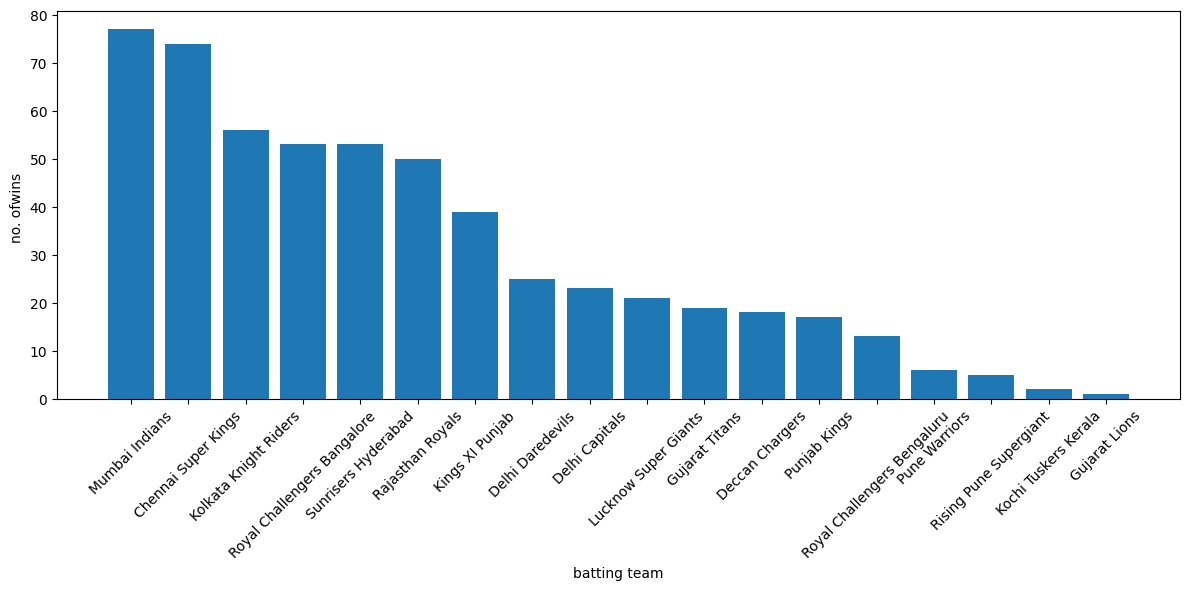

In [ ]:
#22-sept
won=match_df[match_df["match_won_by"]==match_df["batting_team"]]
won_count=won['batting_team'].value_counts()
plt.figure(figsize=(12,6))
plt.bar(won_count.index,won_count.values)
plt.xlabel("batting team")
plt.ylabel("no. ofwins ")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
match_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1218 entries, 0 to 1242
Data columns (total 52 columns):
 #   Column                             Non-Null Count  Dtype 
---  ------                             --------------  ----- 
 0   match_id                           1218 non-null   int64 
 1   batting_team                       1218 non-null   object
 2   bowling_team                       1218 non-null   object
 3   toss_winner                        1218 non-null   object
 4   toss_decision                      1218 non-null   object
 5   venue                              1218 non-null   object
 6   city                               1218 non-null   object
 7   season                             1218 non-null   object
 8   match_won_by                       1218 non-null   object
 9   target                             1218 non-null   int64 
 10  team1_toss                         1218 non-null   int64 
 11  bat_first                          1218 non-null   int64 
 12  team1_Chenn

In [ ]:
match_df["target"].value_counts()

,count
target,
0,666
1,552


In [ ]:
team1_cols=[]
for i in match_df.columns:
  if i.startswith("team1_"):
    team1_cols.append(i)
team2_cols=[]
for i in match_df.columns:
  if i.startswith("team2_"):
    team2_cols.append(i)
match_df.drop(columns=team1_cols+team2_cols,inplace=True)


In [ ]:
match_df.shape

(1218, 13)

In [ ]:
match_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1218 entries, 0 to 1242
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   match_id       1218 non-null   int64 
 1   batting_team   1218 non-null   object
 2   bowling_team   1218 non-null   object
 3   toss_winner    1218 non-null   object
 4   toss_decision  1218 non-null   object
 5   venue          1218 non-null   object
 6   city           1218 non-null   object
 7   season         1218 non-null   object
 8   match_won_by   1218 non-null   object
 9   target         1218 non-null   int64 
 10  bat_first      1218 non-null   int64 
 11  year           1218 non-null   int32 
 12  month          1218 non-null   int32 
dtypes: int32(2), int64(3), object(8)
memory usage: 156.0+ KB


In [ ]:
match_df.head()

,match_id,batting_team,bowling_team,toss_winner,toss_decision,venue,city,season,match_won_by,target,bat_first,year,month
0,335982,Kolkata Knight Riders,Royal Challengers Bangalore,Royal Challengers Bangalore,field,M Chinnaswamy Stadium,Bangalore,2007/08,Kolkata Knight Riders,1,0,2008,4
1,335983,Chennai Super Kings,Kings XI Punjab,Chennai Super Kings,bat,"Punjab Cricket Association Stadium, Mohali",Chandigarh,2007/08,Chennai Super Kings,1,1,2008,4
2,335984,Rajasthan Royals,Delhi Daredevils,Rajasthan Royals,bat,Feroz Shah Kotla,Delhi,2007/08,Delhi Daredevils,0,1,2008,4
3,335985,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Wankhede Stadium,Mumbai,2007/08,Royal Challengers Bangalore,0,1,2008,4
4,335986,Deccan Chargers,Kolkata Knight Riders,Deccan Chargers,bat,Eden Gardens,Kolkata,2007/08,Kolkata Knight Riders,0,1,2008,4


In [ ]:
match_df.columns.tolist()

['match_id',
 'batting_team',
 'bowling_team',
 'toss_winner',
 'toss_decision',
 'venue',
 'city',
 'season',
 'match_won_by',
 'target',
 'bat_first',
 'year',
 'month']

In [ ]:
match_df["batting_team"].unique()


array(['Kolkata Knight Riders', 'Chennai Super Kings', 'Rajasthan Royals',
       'Mumbai Indians', 'Deccan Chargers', 'Kings XI Punjab',
       'Royal Challengers Bangalore', 'Delhi Daredevils',
       'Kochi Tuskers Kerala', 'Pune Warriors', 'Sunrisers Hyderabad',
       'Rising Pune Supergiants', 'Gujarat Lions',
       'Rising Pune Supergiant', 'Delhi Capitals', 'Punjab Kings',
       'Lucknow Super Giants', 'Gujarat Titans',
       'Royal Challengers Bengaluru'], dtype=object)

In [ ]:
team_mapping={
    "Delhi Daredevils":"Delhi Capitals",
    "Royal Challengers Bangalore":"Royal Challengers Bengaluru",
    "Kings XI Punjab":"Punjab Kings",
    "Rising Pune Supergiants":"Rising Pune Supergiant"

}
match_df["batting_team"]=match_df['batting_team'].replace(team_mapping)
match_df["bowling_team"]=match_df['bowling_team'].replace(team_mapping)
match_df["match_won_by"]=match_df['match_won_by'].replace(team_mapping)
match_df["toss_winner"]=match_df['toss_winner'].replace(team_mapping)

In [ ]:
match_df["batting_team"].nunique()



15

In [ ]:
match_df["bowling_team"].nunique()

15

In [ ]:

match_df["toss_winner"].nunique()

15

In [ ]:
match_df=pd.get_dummies(match_df, columns=["batting_team","bowling_team","toss_winner"],drop_first=True)

In [ ]:
match_df.shape

(1218, 52)

In [ ]:
match_df.head()

,match_id,toss_decision,venue,city,season,match_won_by,target,bat_first,year,month,...,toss_winner_Kochi Tuskers Kerala,toss_winner_Kolkata Knight Riders,toss_winner_Lucknow Super Giants,toss_winner_Mumbai Indians,toss_winner_Pune Warriors,toss_winner_Punjab Kings,toss_winner_Rajasthan Royals,toss_winner_Rising Pune Supergiant,toss_winner_Royal Challengers Bengaluru,toss_winner_Sunrisers Hyderabad
0,335982,field,M Chinnaswamy Stadium,Bangalore,2007/08,Kolkata Knight Riders,1,0,2008,4,...,False,False,False,False,False,False,False,False,True,False
1,335983,bat,"Punjab Cricket Association Stadium, Mohali",Chandigarh,2007/08,Chennai Super Kings,1,1,2008,4,...,False,False,False,False,False,False,False,False,False,False
2,335984,bat,Feroz Shah Kotla,Delhi,2007/08,Delhi Capitals,0,1,2008,4,...,False,False,False,False,False,False,True,False,False,False
3,335985,bat,Wankhede Stadium,Mumbai,2007/08,Royal Challengers Bengaluru,0,1,2008,4,...,False,False,False,True,False,False,False,False,False,False
4,335986,bat,Eden Gardens,Kolkata,2007/08,Kolkata Knight Riders,0,1,2008,4,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
match_df=match_df.astype({col:int for col in match_df.select_dtypes(include="bool").columns})

In [ ]:
match_df.dtypes[match_df.dtypes=="object"]

,0
toss_decision,object
venue,object
city,object
season,object
match_won_by,object


In [ ]:
match_df.drop("match_won_by",axis=1,inplace=True)

In [ ]:
match_df.drop("match_id",axis=1,inplace=True)

In [ ]:
match_df.columns.tolist()

['toss_decision',
 'venue',
 'city',
 'season',
 'target',
 'bat_first',
 'year',
 'month',
 'batting_team_Deccan Chargers',
 'batting_team_Delhi Capitals',
 'batting_team_Gujarat Lions',
 'batting_team_Gujarat Titans',
 'batting_team_Kochi Tuskers Kerala',
 'batting_team_Kolkata Knight Riders',
 'batting_team_Lucknow Super Giants',
 'batting_team_Mumbai Indians',
 'batting_team_Pune Warriors',
 'batting_team_Punjab Kings',
 'batting_team_Rajasthan Royals',
 'batting_team_Rising Pune Supergiant',
 'batting_team_Royal Challengers Bengaluru',
 'batting_team_Sunrisers Hyderabad',
 'bowling_team_Deccan Chargers',
 'bowling_team_Delhi Capitals',
 'bowling_team_Gujarat Lions',
 'bowling_team_Gujarat Titans',
 'bowling_team_Kochi Tuskers Kerala',
 'bowling_team_Kolkata Knight Riders',
 'bowling_team_Lucknow Super Giants',
 'bowling_team_Mumbai Indians',
 'bowling_team_Pune Warriors',
 'bowling_team_Punjab Kings',
 'bowling_team_Rajasthan Royals',
 'bowling_team_Rising Pune Supergiant',
 'bowl

In [ ]:
match_df["city"].unique()

array(['Bangalore', 'Chandigarh', 'Delhi', 'Mumbai', 'Kolkata', 'Jaipur',
       'Hyderabad', 'Chennai', 'Cape Town', 'Port Elizabeth', 'Durban',
       'Centurion', 'East London', 'Johannesburg', 'Kimberley',
       'Bloemfontein', 'Ahmedabad', 'Cuttack', 'Nagpur', 'Dharamsala',
       'Kochi', 'Indore', 'Visakhapatnam', 'Pune', 'Raipur', 'Ranchi',
       'Abu Dhabi', 'Unknown', 'Rajkot', 'Kanpur', 'Bengaluru', 'Dubai',
       'Sharjah', 'Navi Mumbai', 'Lucknow', 'Guwahati', 'Mohali',
       'New Chandigarh'], dtype=object)

In [ ]:
match_df.dtypes[match_df.dtypes=="object"]

,0
toss_decision,object
venue,object
city,object
season,object


In [ ]:
match_df["season"]=pd.to_numeric(match_df["season"], errors="coerce")

In [ ]:
match_df["season"].unique()

array([  nan, 2009., 2011., 2012., 2013., 2014., 2015., 2016., 2017.,
       2018., 2019., 2021., 2022., 2023., 2024., 2025., 2026.])

In [ ]:
match_df["season"]=match_df["season"].fillna(match_df["year"])

In [ ]:
match_df["toss_decision"].unique()

array(['field', 'bat'], dtype=object)

In [ ]:
map_toss_decision={
    "bat":1,
    "field":0
}

In [ ]:
match_df["toss_decision"]=match_df["toss_decision"].map(map_toss_decision)

In [ ]:
match_df["toss_decision"]

,toss_decision
0,0
1,1
2,1
3,1
4,1
...,...
1238,0
1239,0
1240,0
1241,1


In [ ]:
match_df["venue"].unique()

array(['M Chinnaswamy Stadium',
       'Punjab Cricket Association Stadium, Mohali', 'Feroz Shah Kotla',
       'Wankhede Stadium', 'Eden Gardens', 'Sawai Mansingh Stadium',
       'Rajiv Gandhi International Stadium, Uppal',
       'MA Chidambaram Stadium, Chepauk', 'Dr DY Patil Sports Academy',
       'Newlands', "St George's Park", 'Kingsmead', 'SuperSport Park',
       'Buffalo Park', 'New Wanderers Stadium', 'De Beers Diamond Oval',
       'OUTsurance Oval', 'Brabourne Stadium',
       'Sardar Patel Stadium, Motera', 'Barabati Stadium',
       'Brabourne Stadium, Mumbai',
       'Vidarbha Cricket Association Stadium, Jamtha',
       'Himachal Pradesh Cricket Association Stadium', 'Nehru Stadium',
       'Holkar Cricket Stadium',
       'Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium',
       'Subrata Roy Sahara Stadium',
       'Maharashtra Cricket Association Stadium',
       'Shaheed Veer Narayan Singh International Stadium',
       'JSCA International Stadium Complex', 'Sh

In [ ]:
match_df["venue"]=match_df["venue"].str.strip()
match_df["venue"]=match_df["venue"].str.lower()
match_df["city"]=match_df["city"].str.strip()
match_df["city"]=match_df["city"].str.lower()

In [ ]:
match_df["venue"]=match_df["venue"].str.replace(".","",regex=False)

In [ ]:
match_df["city"]=match_df["city"].str.replace(".","",regex=False)

In [ ]:
match_df[["venue"]].duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
1238,True
1239,True
1240,True
1241,True


In [ ]:
match_df[match_df["venue"].str.contains("chinnaswamy")]["venue"].unique()

array(['m chinnaswamy stadium', 'mchinnaswamy stadium',
       'm chinnaswamy stadium, bengaluru'], dtype=object)

In [ ]:
match_df["venue"]=match_df["venue"].replace({"m chinnaswamy stadium":"m chinnaswamy stadium",
                                             "mchinnaswamy stadium":"m chinnaswamy stadium",
                                             "m chinnaswamy stadium, bengaluru":"m chinnaswamy stadium"})

In [ ]:
match_df['venue'].unique()

array(['m chinnaswamy stadium',
       'punjab cricket association stadium, mohali', 'feroz shah kotla',
       'wankhede stadium', 'eden gardens', 'sawai mansingh stadium',
       'rajiv gandhi international stadium, uppal',
       'ma chidambaram stadium, chepauk', 'dr dy patil sports academy',
       'newlands', "st george's park", 'kingsmead', 'supersport park',
       'buffalo park', 'new wanderers stadium', 'de beers diamond oval',
       'outsurance oval', 'brabourne stadium',
       'sardar patel stadium, motera', 'barabati stadium',
       'brabourne stadium, mumbai',
       'vidarbha cricket association stadium, jamtha',
       'himachal pradesh cricket association stadium', 'nehru stadium',
       'holkar cricket stadium',
       'dr ys rajasekhara reddy aca-vdca cricket stadium',
       'subrata roy sahara stadium',
       'maharashtra cricket association stadium',
       'shaheed veer narayan singh international stadium',
       'jsca international stadium complex', 'sheik

In [ ]:
match_df["venue"]=match_df["venue"].str.split(",").str[0].str.strip()

In [ ]:
match_df["venue"].unique()

array(['m chinnaswamy stadium', 'punjab cricket association stadium',
       'feroz shah kotla', 'wankhede stadium', 'eden gardens',
       'sawai mansingh stadium', 'rajiv gandhi international stadium',
       'ma chidambaram stadium', 'dr dy patil sports academy', 'newlands',
       "st george's park", 'kingsmead', 'supersport park', 'buffalo park',
       'new wanderers stadium', 'de beers diamond oval',
       'outsurance oval', 'brabourne stadium', 'sardar patel stadium',
       'barabati stadium', 'vidarbha cricket association stadium',
       'himachal pradesh cricket association stadium', 'nehru stadium',
       'holkar cricket stadium',
       'dr ys rajasekhara reddy aca-vdca cricket stadium',
       'subrata roy sahara stadium',
       'maharashtra cricket association stadium',
       'shaheed veer narayan singh international stadium',
       'jsca international stadium complex', 'sheikh zayed stadium',
       'sharjah cricket stadium', 'dubai international cricket stadium',

In [ ]:
match_df["venue"].nunique()

41

In [ ]:
match_df=pd.get_dummies(match_df,columns=["venue"],drop_first=True,dtype=int)

In [ ]:
match_df.head()

,toss_decision,city,season,target,bat_first,year,month,batting_team_Deccan Chargers,batting_team_Delhi Capitals,batting_team_Gujarat Lions,...,venue_sawai mansingh stadium,venue_shaheed veer narayan singh international stadium,venue_sharjah cricket stadium,venue_sheikh zayed stadium,venue_st george's park,venue_subrata roy sahara stadium,venue_supersport park,venue_vidarbha cricket association stadium,venue_wankhede stadium,venue_zayed cricket stadium
0,0,bangalore,2008.0,1,0,2008,4,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,chandigarh,2008.0,1,1,2008,4,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,delhi,2008.0,0,1,2008,4,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,mumbai,2008.0,0,1,2008,4,0,0,0,...,0,0,0,0,0,0,0,0,1,0
4,1,kolkata,2008.0,0,1,2008,4,1,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
match_df.dtypes[match_df.dtypes=="object"]

,0
city,object


In [ ]:
match_df["city"].unique()

array(['bangalore', 'chandigarh', 'delhi', 'mumbai', 'kolkata', 'jaipur',
       'hyderabad', 'chennai', 'cape town', 'port elizabeth', 'durban',
       'centurion', 'east london', 'johannesburg', 'kimberley',
       'bloemfontein', 'ahmedabad', 'cuttack', 'nagpur', 'dharamsala',
       'kochi', 'indore', 'visakhapatnam', 'pune', 'raipur', 'ranchi',
       'abu dhabi', 'unknown', 'rajkot', 'kanpur', 'bengaluru', 'dubai',
       'sharjah', 'navi mumbai', 'lucknow', 'guwahati', 'mohali',
       'new chandigarh'], dtype=object)

In [ ]:
match_df["city"]=match_df["city"].replace({"bangalore":"bengaluru"})

In [ ]:
match_df["city"].unique()

array(['bengaluru', 'chandigarh', 'delhi', 'mumbai', 'kolkata', 'jaipur',
       'hyderabad', 'chennai', 'cape town', 'port elizabeth', 'durban',
       'centurion', 'east london', 'johannesburg', 'kimberley',
       'bloemfontein', 'ahmedabad', 'cuttack', 'nagpur', 'dharamsala',
       'kochi', 'indore', 'visakhapatnam', 'pune', 'raipur', 'ranchi',
       'abu dhabi', 'unknown', 'rajkot', 'kanpur', 'dubai', 'sharjah',
       'navi mumbai', 'lucknow', 'guwahati', 'mohali', 'new chandigarh'],
      dtype=object)

In [ ]:
match_df=pd.get_dummies(match_df,columns=["city"],dtype=int,drop_first=True)

In [ ]:
match_df.dtypes[match_df.dtypes=="object"]

,0


In [ ]:
match_df.describe()

,toss_decision,season,target,bat_first,year,month,batting_team_Deccan Chargers,batting_team_Delhi Capitals,batting_team_Gujarat Lions,batting_team_Gujarat Titans,...,city_navi mumbai,city_new chandigarh,city_port elizabeth,city_pune,city_raipur,city_rajkot,city_ranchi,city_sharjah,city_unknown,city_visakhapatnam
count,1218.000000,1218.000000,1218.000000,1218.000000,1218.000000,1218.000000,1218.000000,1218.000000,1218.000000,1218.000000,...,1218.000000,1218.000000,1218.000000,1218.000000,1218.000000,1218.000000,1218.000000,1218.000000,1218.000000,1218.000000
mean,0.334975,2017.214286,0.453202,0.334975,2017.214286,4.757800,0.035304,0.096059,0.010673,0.027915,...,0.007389,0.006568,0.005747,0.041872,0.006568,0.007389,0.005747,0.008210,0.039409,0.013957
std,0.472176,5.555655,0.498010,0.472176,5.555655,1.527494,0.184622,0.294793,0.102801,0.164796,...,0.085677,0.080811,0.075623,0.200379,0.080811,0.085677,0.075623,0.090274,0.194646,0.117362
min,0.000000,2008.000000,0.000000,0.000000,2008.000000,3.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,2012.000000,0.000000,0.000000,2012.000000,4.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,2017.000000,0.000000,0.000000,2017.000000,4.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,2022.000000,1.000000,1.000000,2022.000000,5.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,2026.000000,1.000000,1.000000,2026.000000,11.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [ ]:
X=match_df.drop("target",axis=1)
y=match_df["target"]

In [ ]:
X.shape

(1218, 123)

In [ ]:
y.shape

(1218,)

In [ ]:
from sklearn.model_selection import  train_test_split

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
model=LogisticRegression(max_iter=1000)

In [ ]:
model.fit(X_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000)

In [ ]:
y_pred=model.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score

In [ ]:
acc=accuracy_score(y_test,y_pred)


In [ ]:
print(acc)

0.5737704918032787


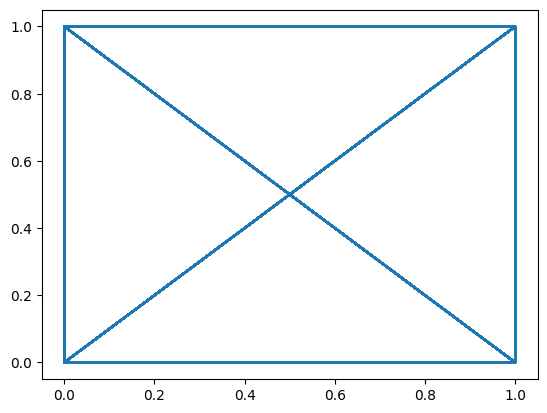

In [ ]:
plt.plot(match_df['target'],match_df['bat_first'])

In [ ]:
match_df.columns.to_list()

['toss_decision',
 'season',
 'target',
 'bat_first',
 'year',
 'month',
 'batting_team_Deccan Chargers',
 'batting_team_Delhi Capitals',
 'batting_team_Gujarat Lions',
 'batting_team_Gujarat Titans',
 'batting_team_Kochi Tuskers Kerala',
 'batting_team_Kolkata Knight Riders',
 'batting_team_Lucknow Super Giants',
 'batting_team_Mumbai Indians',
 'batting_team_Pune Warriors',
 'batting_team_Punjab Kings',
 'batting_team_Rajasthan Royals',
 'batting_team_Rising Pune Supergiant',
 'batting_team_Royal Challengers Bengaluru',
 'batting_team_Sunrisers Hyderabad',
 'bowling_team_Deccan Chargers',
 'bowling_team_Delhi Capitals',
 'bowling_team_Gujarat Lions',
 'bowling_team_Gujarat Titans',
 'bowling_team_Kochi Tuskers Kerala',
 'bowling_team_Kolkata Knight Riders',
 'bowling_team_Lucknow Super Giants',
 'bowling_team_Mumbai Indians',
 'bowling_team_Pune Warriors',
 'bowling_team_Punjab Kings',
 'bowling_team_Rajasthan Royals',
 'bowling_team_Rising Pune Supergiant',
 'bowling_team_Royal Chal

In [ ]:
y

,target
0,1
1,1
2,0
3,0
4,0
...,...
1238,1
1239,1
1240,1
1241,0


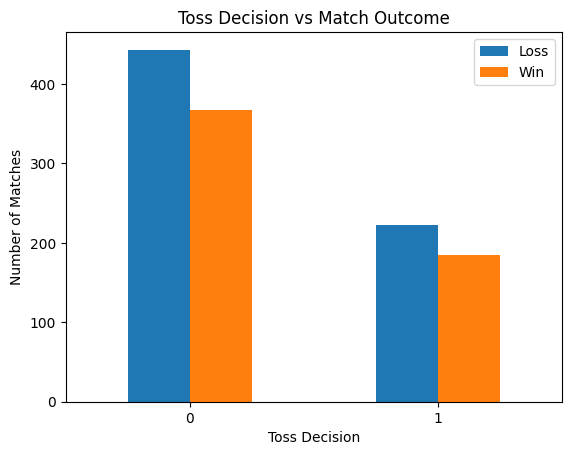

In [ ]:


pd.crosstab(match_df["toss_decision"], match_df["target"]).plot(kind="bar")

plt.xlabel("Toss Decision")
plt.ylabel("Number of Matches")
plt.title("Toss Decision vs Match Outcome")
plt.xticks(rotation=0)
plt.legend(["Loss", "Win"])
plt.savefig("toss_vs_target.png", dpi=300,bbox_inches="tight")

plt.show()

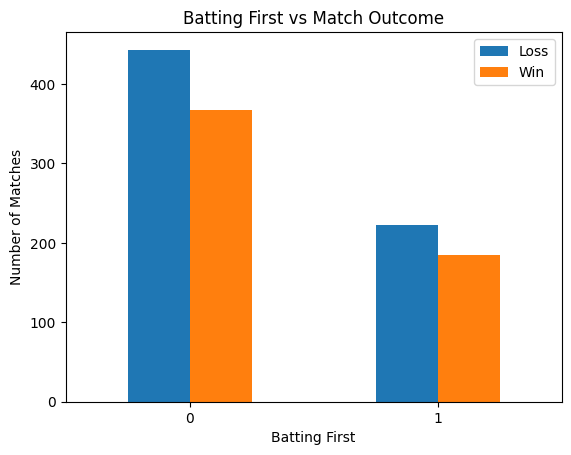

In [ ]:
pd.crosstab(match_df["bat_first"], match_df["target"]).plot(kind="bar")

plt.xlabel("Batting First")
plt.ylabel("Number of Matches")
plt.title("Batting First vs Match Outcome")
plt.xticks(rotation=0)
plt.legend(["Loss", "Win"])
plt.savefig("bat_vs_target.png", dpi=300,bbox_inches="tight")

plt.show()

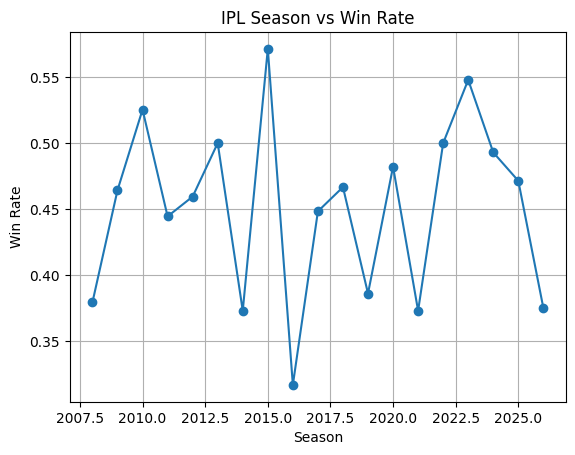

In [ ]:
season_result = match_df.groupby("season")["target"].mean()

season_result.plot(kind="line", marker="o")

plt.xlabel("Season")
plt.ylabel("Win Rate")
plt.title("IPL Season vs Win Rate")
plt.grid(True)
plt.savefig("season_vs_win_rate.png", dpi=300,bbox_inches="tight")

plt.show()

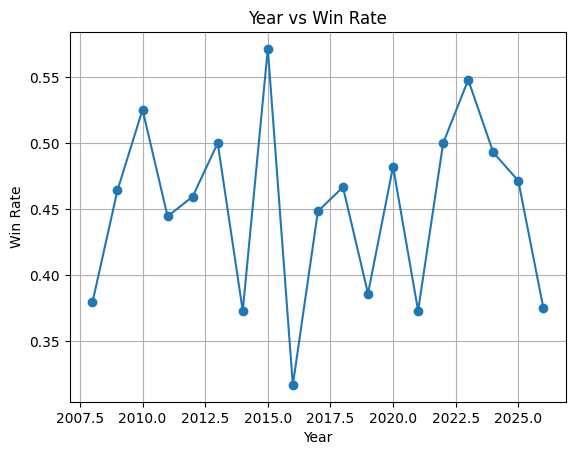

In [ ]:
year_result = match_df.groupby("year")["target"].mean()

year_result.plot(kind="line", marker="o")

plt.xlabel("Year")
plt.ylabel("Win Rate")
plt.title("Year vs Win Rate")
plt.grid(True)
plt.savefig("year_vs_win_rate.png", dpi=300,bbox_inches="tight")

plt.show()

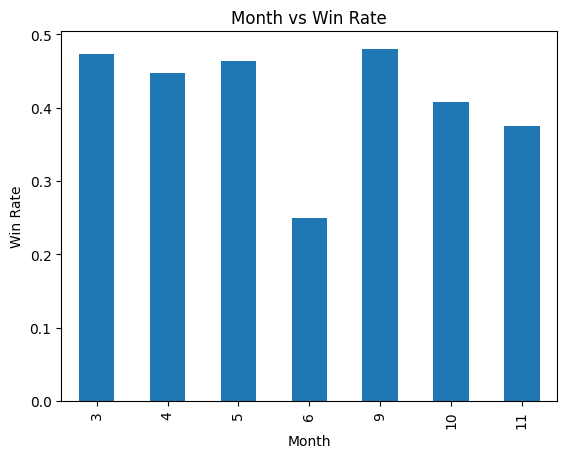

In [ ]:
month_result = match_df.groupby("month")["target"].mean()

month_result.plot(kind="bar")

plt.xlabel("Month")
plt.ylabel("Win Rate")
plt.title("Month vs Win Rate")
plt.savefig("month_vs_win_rate.png", dpi=300,bbox_inches="tight")
plt.show()